Dataset:
   Age  Annual Income  Spending Score
0   56             84              61
1   69             86              48
2   46             41              19
3   32             23               4
4   60             76              35

Dataset Shape: (200, 3)


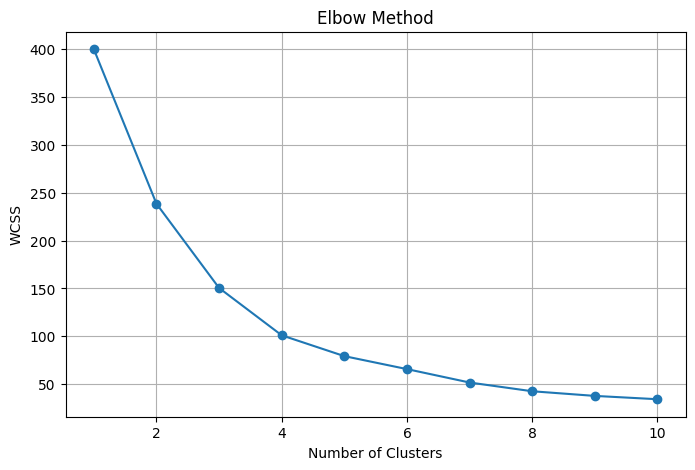


Clustered Dataset:
   Age  Annual Income  Spending Score  Cluster
0   56             84              61        4
1   69             86              48        4
2   46             41              19        1
3   32             23               4        1
4   60             76              35        1
5   25             51              64        3
6   38            111              49        4
7   56             65              17        1
8   36            120              44        4
9   40             58              92        3

Number of Customers in Each Cluster:
Cluster
0    37
1    44
2    22
3    51
4    46
Name: count, dtype: int64


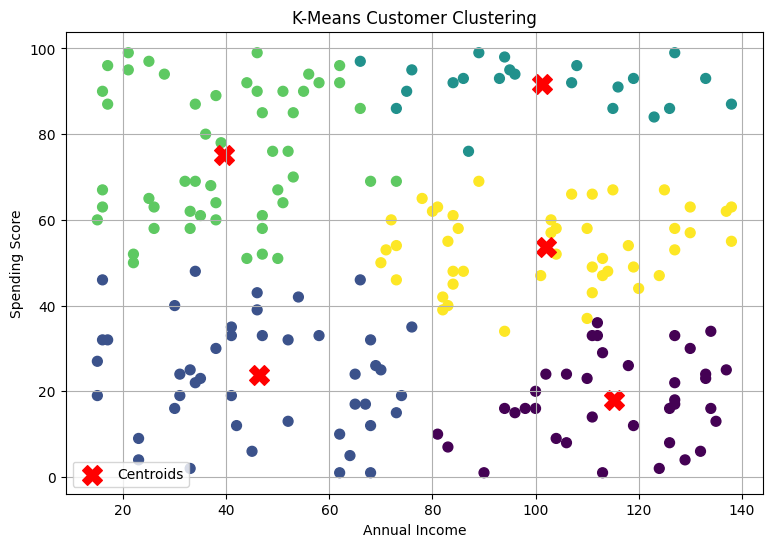


Cluster Centers:
   Annual Income  Spending Score
0     115.135135       17.945946
1      46.272727       23.704545
2     101.181818       91.590909
3      39.549020       75.215686
4     102.108696       53.695652


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Create Dataset
np.random.seed(42)

df = pd.DataFrame({
    'Age': np.random.randint(18, 70, 200),
    'Annual Income': np.random.randint(15, 140, 200),
    'Spending Score': np.random.randint(1, 100, 200)
})

print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# 2. Select Features
X = df[['Annual Income', 'Spending Score']]

# 3. Standardize Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Find Optimal Number of Clusters using Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# 5. Plot Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid()
plt.show()

# 6. Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

# 7. Display Clustered Dataset
print("\nClustered Dataset:")
print(df.head(10))

print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# 8. Visualize Clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    df['Annual Income'],
    df['Spending Score'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("K-Means Customer Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.grid()
plt.show()

# 9. Display Cluster Centers
print("\nCluster Centers:")
print(pd.DataFrame(
    centers,
    columns=['Annual Income', 'Spending Score']
))
